# 🚀 Practice Day 57

**📅 Date:** 2026-11-06  
**📁 Category:** Phase 1 · 데이터 클리닝 (Round 5/5)


---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Diagnose data quality issues in messy furniture store orders (missing values, duplicates, type errors, inconsistent categories, price outliers)
  (지저분한 가구 쇼핑몰 주문 데이터의 품질 문제 진단: 결측치·중복행·타입 오류·표기 불일치·가격 이상값)
- Clean the dataset so it's reliable enough to analyze
  (분석 가능한 수준으로 데이터 정제하기)
- Summarize price by category once the data is clean
  (정제 후 카테고리별 가격 요약하기)

---
# 📂 Dataset

**Dataset Name:** Hearth & Home Furniture — Order Records (Raw) / Hearth & Home 가구 쇼핑몰 — 주문 데이터 (원본, 지저분한 버전)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 284 raw furniture order records (single table) across 6 categories (Sofas, Tables, Chairs, Beds, Storage, Lighting). Deliberately includes missing values, exact duplicate rows, a `price` column mixing numbers with junk text, inconsistent capitalization/spacing in `category`, and out-of-range price outliers (negative and implausibly high values). Prices are in USD.
(284건의 가구 쇼핑몰 원본 주문 데이터입니다(단일 테이블). 6개 카테고리(Sofas/Tables/Chairs/Beds/Storage/Lighting)에 걸쳐 있습니다. 결측치, 완전 중복행, 숫자와 문자가 섞인 price 컬럼, category의 대소문자/공백 표기 불일치, 범위를 벗어난 price 이상값(음수·비현실적 고액)이 의도적으로 섞여 있습니다. 가격은 USD입니다.)

## Dataset Preview

In [44]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate messy furniture store order records ---
n_clean = 270
n_dupe = 14

categories = ['Sofas', 'Tables', 'Chairs', 'Beds', 'Storage', 'Lighting']
cat_w = [0.16, 0.18, 0.22, 0.14, 0.16, 0.14]
base_price = {'Sofas': 850, 'Tables': 320, 'Chairs': 145, 'Beds': 620, 'Storage': 280, 'Lighting': 95}  # USD

cat_choice = rng.choice(categories, size=n_clean, p=cat_w)
order_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 220, size=n_clean), unit='D')

price = np.array([base_price[c] for c in cat_choice]) * rng.normal(1.0, 0.10, n_clean)
price = price.round(0).astype(int)  # nearest USD

df = pd.DataFrame({
    'order_id': [f'F{str(i).zfill(4)}' for i in range(1, n_clean + 1)],
    'category': cat_choice,
    'price': price,
    'order_date': order_dates
})
df['category'] = df['category'].astype(object)
df['price'] = df['price'].astype(object)
df['order_date'] = df['order_date'].astype(object)

# --- inject realistic messiness (this is what you'll clean up below) ---

# 1) Inconsistent text formatting: category casing/whitespace
mess_idx = rng.choice(df.index, size=int(n_clean * 0.4), replace=False)
for i in mess_idx:
    base = df.loc[i, 'category']
    df.loc[i, 'category'] = rng.choice([base.lower(), base.upper(), ' ' + base, base + ' '])

# 2) price: non-numeric junk values + unrealistic outliers
used_idx = set()
price_junk_vals = ['N/A', 'pending', 'TBD', 'cancelled']
junk_idx = rng.choice(df.index, size=10, replace=False)
used_idx.update(junk_idx.tolist())
for j, i in enumerate(junk_idx):
    df.loc[i, 'price'] = price_junk_vals[j % len(price_junk_vals)]

avail = df.index.difference(list(used_idx))
outlier_idx = rng.choice(avail, size=8, replace=False)
used_idx.update(outlier_idx.tolist())
outlier_vals = [-80, -25, 15200, 9800, -12, 11500, -45, 13000]  # USD
for j, i in enumerate(outlier_idx):
    df.loc[i, 'price'] = outlier_vals[j % len(outlier_vals)]

# 3) Missing values scattered across columns
price_avail = df.index.difference(list(used_idx))
df.loc[rng.choice(price_avail, size=9, replace=False), 'price'] = np.nan
for col, n_missing in [('category', 7), ('order_date', 8)]:
    df.loc[rng.choice(df.index, size=n_missing, replace=False), col] = np.nan

# 4) Duplicate rows (simulates a checkout retry creating duplicate order records)
dupe_rows = df.sample(n=n_dupe, random_state=7)
df = pd.concat([df, dupe_rows], ignore_index=True)

# Shuffle so duplicates aren't sitting next to their source row
df = df.sample(frac=1, random_state=99).reset_index(drop=True)

df.head(10)


,order_id,category,price,order_date
0,F0144,Beds,523,2024-07-29 00:00:00
1,F0204,SOFAS,741,2024-02-29 00:00:00
2,F0008,Storage,295,2024-05-10 00:00:00
3,F0219,Lighting,100,2024-01-29 00:00:00
4,F0003,Storage,293,2024-02-12 00:00:00
5,F0120,Beds,523,2024-03-04 00:00:00
6,F0160,Storage,291,2024-01-21 00:00:00
7,F0201,Storage,287,2024-06-28 00:00:00
8,F0016,tables,316,2024-04-20 00:00:00
9,F0051,Tables,331,2024-06-25 00:00:00


## Dataset Information

In [45]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 284 entries, 0 to 283
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   order_id    284 non-null    str   
 1   category    277 non-null    object
 2   price       275 non-null    object
 3   order_date  276 non-null    object
dtypes: object(3), str(1)
memory usage: 9.0+ KB

Shape: (284, 4)


,order_id,category,price,order_date
count,284,277,275,276
unique,270,29,197,151
top,F0003,Chairs,141,2024-06-11 00:00:00
freq,2,33,5,6


---
# ❓ Business Questions

1. **(Analysis)** How many missing values exist in each column, and how many exact duplicate rows are in the dataset?
   (각 컬럼별 결측치 개수와 완전 중복행의 개수는?)
2. **(Analysis)** How many rows have a non-numeric/invalid `price` value, and what inconsistent formats appear in `category`?
   (`price`에서 숫자로 변환되지 않는 값은 몇 건이며, `category`에는 어떤 표기 불일치가 나타나는가?)
3. **(Analysis)** Among valid numeric prices, how many fall outside a realistic range (e.g., negative or implausibly high)?
   (유효한 숫자형 price 중 현실적인 범위를 벗어난 값(음수 또는 비현실적 고액)은 몇 건인가?)
4. **(Visualization)** After cleaning, what is the average price by category?
   (정제 후, 카테고리별 평균 가격은?)
5. **(Visualization)** After cleaning, what does the overall price distribution look like?
   (정제 후, 전체 가격 분포는 어떤 모습인가?)

---
# 🔍 Data Cleaning Check


In [46]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
order_id      0
category      7
price         9
order_date    8
dtype: int64

Duplicate rows: 14

Dtypes
order_id         str
category      object
price         object
order_date    object
dtype: object

Column names
['order_id', 'category', 'price', 'order_date']

Text columns — unique counts
order_id      270
category       29
price         197
order_date    151
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** How many missing values exist in each column, and how many exact duplicate rows are in the dataset? (각 컬럼별 결측치 개수와 완전 중복행의 개수는?)

**Result:**  
`category` has **7** missing values, `price` has **9**, and `order_date` has **8**. There are **14** exact duplicate rows.  
(`category` 결측은 **7**, `price`는 **9**, `order_date`는 **8**입니다. 완전 중복행은 **14**건입니다.)  

**Insight:**  
Those missing cells add up to **24**, and `price` has the most. `order_id` has none.  
(결측 칸을 더하면 **24**이고, `price`가 가장 많습니다. `order_id`는 결측이 없습니다.)

In [47]:
# Question 1: missing values per column + exact duplicate row count
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

cleaned_df = df.copy()
cleaned_df = cleaned_df.drop_duplicates().reset_index(drop=True)
# A row missing category, price, or order_date cannot be used below.
cleaned_df = cleaned_df.dropna().reset_index(drop=True)


order_id      0
category      7
price         9
order_date    8
dtype: int64

Duplicate rows: 14


## Question 2

**Question:** How many rows have a non-numeric/invalid `price` value, and what inconsistent formats appear in `category`? (`price` 무효값 건수와 표기 불일치는?)

**Result:**  
**8** prices are text, not numbers: `N/A` **3**, `pending` **2**, `TBD` **2**, and `cancelled` **1**. The same category is also written with different case and spaces, such as `Chairs` (**30**), `CHAIRS` (**7**), and ` chairs` (**5**).  
(가격 **8**건은 숫자가 아닙니다. `N/A` **3**, `pending` **2**, `TBD` **2**, `cancelled` **1**입니다. 같은 카테고리도 대소문자와 공백이 다릅니다. 예를 들어 `Chairs` **30**, `CHAIRS` **7**, ` chairs` **5**입니다.)  

**Insight:**  
The **8** text prices are the junk strings, separate from the **9** missing prices in Question 1.  
(텍스트 가격 **8**건은 결측 **9**건과는 다른 쓰레기 값입니다.)

In [48]:
# Question 2: invalid price values + category formatting inconsistencies
numeric_price = pd.to_numeric(cleaned_df['price'], errors='coerce')
invalid_price = cleaned_df['price'].notna() & numeric_price.isna()
print("Invalid price rows:", int(invalid_price.sum()))
print(cleaned_df.loc[invalid_price, 'price'].value_counts())

print("\nCategory formats")
print(cleaned_df['category'].value_counts())

cleaned_df = cleaned_df.loc[~invalid_price].copy()
cleaned_df['category'] = cleaned_df['category'].str.strip().str.title()
cleaned_df['price'] = pd.to_numeric(cleaned_df['price'])


Invalid price rows: 8
price
N/A          3
pending      2
TBD          2
cancelled    1
Name: count, dtype: int64

Category formats
category
Chairs       30
Tables       25
Sofas        25
Storage      24
Beds         20
Lighting     20
 Tables       8
SOFAS         7
tables        7
CHAIRS        7
storage       6
Sofas         6
Chairs        6
 Sofas        6
 Storage      5
chairs        5
 Chairs       5
beds          5
 Beds         4
Lighting      4
Beds          4
sofas         3
BEDS          3
 Lighting     2
STORAGE       2
Storage       2
Tables        2
lighting      2
LIGHTING      1
Name: count, dtype: int64


## Question 3

**Question:** Among valid numeric prices, how many fall outside a realistic range? (유효한 숫자형 price 중 현실적 범위를 벗어난 값은?)

**Result:**  
**8** numeric prices are outside $0–$2,000. Four are negative (**-$80**, **-$45**, **-$25**, **-$12**) and four are far too high (**$9,800**, **$11,500**, **$13,000**, **$15,200**).  
(숫자 가격 **8**건이 $0–$2,000 밖입니다. 넷은 음수(**-$80**, **-$45**, **-$25**, **-$12**)이고, 넷은 너무 높습니다(**$9,800**, **$11,500**, **$13,000**, **$15,200**).)  

**Insight:**  
The highest out-of-range price is **$15,200**, which is **$14,359** above the highest cleaned category average on the bar chart (**$841**).  
(범위 밖 최고 가격은 **$15,200**이고, 막대그래프의 가장 높은 평균 **$841**보다 **$14,359** 큽니다.)

In [49]:
# Question 3: unrealistic price values among valid numeric prices
# Category bases are $95–$850, and the other numeric prices stay under $1,000.
# Below $0 or above $2,000 is not a real order price.
out_of_range = (cleaned_df['price'] < 0) | (cleaned_df['price'] > 2000)
print("Out-of-range prices:", int(out_of_range.sum()))
print(cleaned_df.loc[out_of_range, ['order_id', 'category', 'price']].sort_values('price'))

cleaned_df = cleaned_df.loc[~out_of_range].reset_index(drop=True)


Out-of-range prices: 8
    order_id  category  price
78     F0172    Chairs    -80
182    F0195     Sofas    -45
151    F0136     Sofas    -25
169    F0109     Sofas    -12
95     F0143  Lighting   9800
212    F0023  Lighting  11500
103    F0209     Sofas  13000
124    F0194   Storage  15200


---
# 📈 Visualization

**Chart 1:** Bar chart — average price by category (막대그래프: 카테고리별 평균 가격)

*Interpretation:*  
Sofas have the highest average price at **$841**, and Lighting the lowest at **$99**. Beds are second at **$619**.  
(Sofas 평균이 **$841**로 가장 높고 Lighting이 **$99**로 가장 낮습니다. Beds는 **$619**로 두 번째입니다.)  

---

**Chart 2:** Histogram — distribution of price (히스토그램: 가격 분포)

*Interpretation:*  
Prices bunch below about **$400** and again from about **$600** to **$1,000**, with a gap between those bands.  
(가격은 약 **$400** 아래와 약 **$600**–**$1,000**에 몰려 있고, 그 사이는 비어 있습니다.)


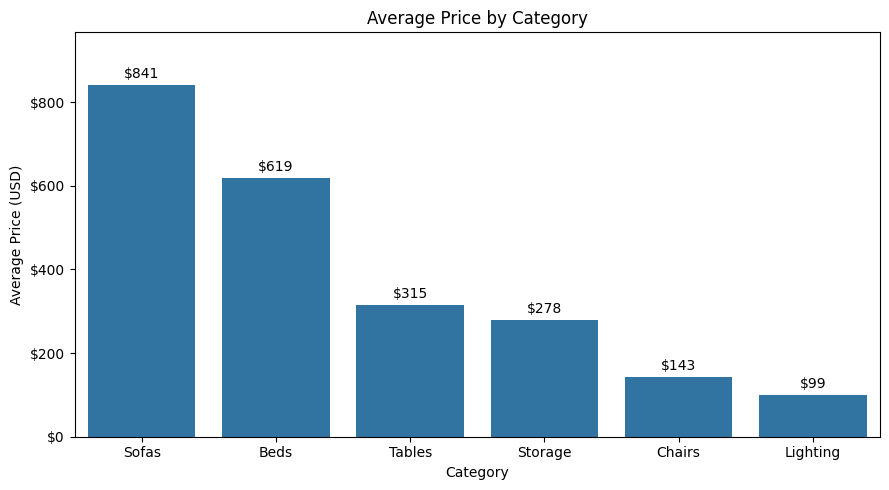

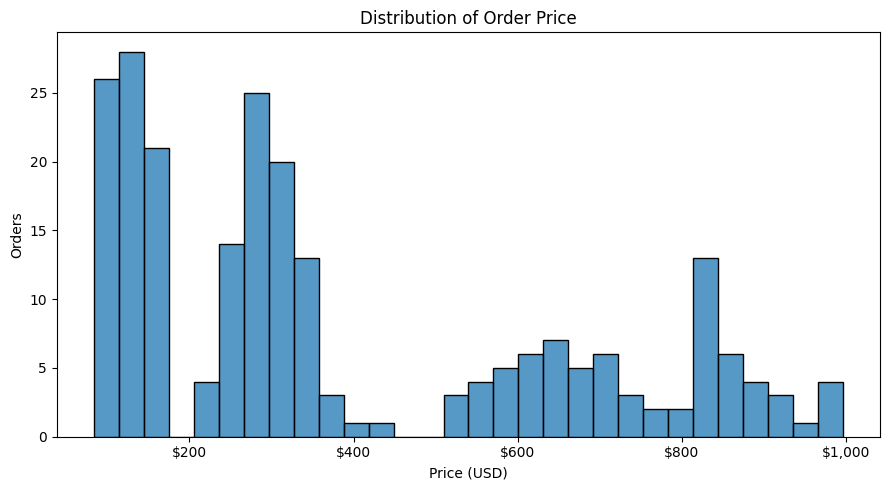

In [50]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: average price by category (bar), highest average first
avg_price = cleaned_df.groupby('category')['price'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=avg_price.index, y=avg_price.values, ax=ax, errorbar=None)
ax.set_title('Average Price by Category')
ax.set_xlabel('Category')
ax.set_ylabel('Average Price (USD)')
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.bar_label(ax.containers[0], fmt='${:.0f}', padding=3)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

# Chart 2: distribution of price (histogram)
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(x='price', bins=30, data=cleaned_df, ax=ax)
ax.set_title('Distribution of Order Price')
ax.set_xlabel('Price (USD)')
ax.set_ylabel('Orders')
ax.xaxis.set_major_formatter('${x:,.0f}')
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- The raw file has **14** duplicate rows and **24** missing cells across `category`, `price`, and `order_date`.  
  (원본에는 중복행 **14**건과, `category`·`price`·`order_date` 결측을 더한 **24**칸이 있습니다.)  
- **8** prices are junk text, and another **8** numeric prices sit outside $0–$2,000.  
  (가격 **8**건은 쓰레기 텍스트이고, 숫자 가격 **8**건은 $0–$2,000 밖입니다.)  
- After cleaning, the average price runs from Lighting at **$99** to Sofas at **$841**.  
  (정제한 뒤 평균 가격은 Lighting **$99**에서 Sofas **$841**까지입니다.)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Remove the **14** duplicate rows and the rows with missing `category`, `price`, or `order_date` before reporting prices.  
   (가격을 보고하기 전에 중복행 **14**건과 `category`, `price`, `order_date` 결측 행을 뺍니다.)  
2. Collapse category spellings such as `Chairs`, `CHAIRS`, and ` chairs` into one name.  
   (`Chairs`, `CHAIRS`, ` chairs`처럼 나뉜 표기를 하나의 이름으로 합칩니다.)  
3. Drop the **8** out-of-range prices, including **-$80** and **$15,200**, before comparing category averages.  
   (카테고리 평균을 비교하기 전에 **-$80**과 **$15,200**을 포함한 범위 밖 가격 **8**건을 뺍니다.)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- I put the checks for Questions 1–3 into the Question 1 cells.  
  (Question 1–3 확인을 Question 1 칸에 한꺼번에 넣었습니다.)  
- I counted duplicate rows after dropping them, so the count was 0.  
  (중복행을 지운 뒤에 세서 개수가 0이 되었습니다.)  
-   


---
# ✅ What I Learned
*Today's biggest lesson*

- Count a problem on the raw column, then fix it.  
  (문제는 원본 열에서 센 다음 고칩니다.)  
- Junk text such as `N/A` has to be counted before `to_numeric`, because coerce turns it into missing.  
  (`N/A` 같은 텍스트는 `to_numeric` 전에 세야 합니다. coerce는 그 값을 결측으로 바꿉니다.)  
-   


---
# 🧠 Reflection

**What was difficult?**  
Deciding which cleaning step belongs to Questions 1–3.  
(어떤 정제 단계가 Question 1–3 중 어디에 속하는지 정하는 것)

**Why?**  
I put the code in one cell and counted the duplicates after dropping them. `to_numeric` with `errors="coerce"` also turns junk text into missing values, so that count disappears.  
(코드를 한 칸에 넣었고 중복행을 지운 뒤에 셈. `to_numeric`의 `errors="coerce"`는 쓰레기 텍스트를 결측으로 바꿔서 그 개수가 사라짐)

**How did I solve it?**  
Split the code into Questions 1–3, and each cell prints the count before it fixes the data.  
(코드를 Question 1–3으로 나누고, 각 칸이 데이터를 고치기 전에 개수를 출력함)

**What would I do differently next time?**  
Write the count line before the fix line in every cleaning step.  
(모든 정제 단계에서 개수를 세는 줄을 고치는 줄보다 먼저 쓰기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
I can separate missing values, junk text, and out-of-range prices.  
(결측, 쓰레기 텍스트, 범위 밖 가격을 구분할 수 있습니다.)  

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★★☆☆☆☆  


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Day 58: Visualization basics  
  (Day 58: 시각화 기초)  
